# Prédiction de la Popularité des Titres Spotify
**Formation :** Master 1 SSD — Université Grenoble Alpes (UGA)  
**Binôme :** Ramez Dahouathi & Noé Desanlis  

**Objectif :** Ce projet vise à prédire le score de popularité continu ($[0, 100]$) de titres Spotify inédits à partir de leurs caractéristiques acoustiques, de leur structure musicale et de leurs métadonnées. Notre approche intègre le traitement des valeurs manquantes et l'encodage catégoriel (*One-Hot Encoding*) des genres, avant d'entraîner et d'optimiser des modèles de régression par arbres (`DecisionTreeRegressor` et `RandomForestRegressor`) évalués selon la racine de l'erreur quadratique moyenne (RMSE).

In [30]:
# Les libreries necessiaires pour le projet
import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.metrics import root_mean_squared_error

from pathlib import Path

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

In [31]:

data_dir = Path("../data")

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")
print(f"Dimensions test: {test.shape[0]} lignes, {test.shape[1]} colonnes")
print(f"Dimensions train: {train.shape[0]} lignes, {train.shape[1]} colonnes")
display(train.head(5))

Dimensions test: 22800 lignes, 20 colonnes
Dimensions train: 91200 lignes, 21 colonnes


,id,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,0.598,7,-6.984,1,0.0304,0.00511,0.000000,0.176,0.0466,148.014,4,world-music
1,1,2dp5I5MJ8bQQHDoFaNRFtX,Internal Rot,Grieving Birth,Failed Organum,11,93933,False,0.171,0.997,7,-3.586,1,0.1180,0.00521,0.801000,0.420,0.0294,122.223,4,grindcore
2,2,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,9,-10.071,0,0.1440,0.61300,0.001910,0.195,0.0887,75.564,3,iranian
3,3,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,6,-5.598,1,0.0279,0.40600,0.000197,0.111,0.5980,109.991,3,rock
4,4,4bY2oZGA5Br3pTE1Jd1IfY,Nogizaka46,バレッタ TypeD,月の大きさ,57,236293,False,0.555,0.941,9,-3.294,0,0.0481,0.48400,0.000000,0.266,0.8130,92.487,4,j-idol


## 1. Prétraitement et Nettoyage des Données
Nous analysons d'abord la proportion de valeurs manquantes dans les ensembles d'entraînement et de test, puis nous supprimons les métadonnées textuelles à haute cardinalité (`track_id`, `artists`, `album_name`, `track_name`) non directement exploitables par les arbres de décision.

In [32]:
def check_missing_data(df, dataset_name):
    missing_count = df.isnull().sum()
    missing_pct = (missing_count / len(df)) * 100
    missing_table = pd.DataFrame({'Missing Count': missing_count,'Percentage (%)': missing_pct.round(4)})
    missing_table = missing_table[missing_table['Missing Count'] > 0]
    
    print(f"--- Missing Values in {dataset_name} (Total rows: {len(df)}) ---")
    if missing_table.empty:
        print("No missing values found!\n")
    else:
        display(missing_table.sort_values(by='Percentage (%)', ascending=False))

check_missing_data(train, "Train Set")
check_missing_data(test, "Test Set")

--- Missing Values in Train Set (Total rows: 91200) ---
No missing values found!

--- Missing Values in Test Set (Total rows: 22800) ---
No missing values found!



Eh bien, c’est tout à fait normal, car il s’agit d’un défi Kaggle ; notre jeu de données ne devrait donc contenir aucune valeur nulle.

In [33]:
# on efface les colonnes nécessaires pour le modèle
cols_to_drop = ['id','track_id', 'artists', 'album_name', 'track_name']
test_ids = test['id'].copy()
train_clean = train.drop(columns= cols_to_drop)
test_clean = test.drop(columns= cols_to_drop)

# on convertis le Boulean en int pour le model
train_clean['explicit'] = train_clean['explicit'].astype(int)
test_clean['explicit'] = test_clean['explicit'].astype(int)

print(f"Cleaned Train : {train_clean.shape}")
print(f"Cleaned Test :  {test_clean.shape}")
display(train_clean.head(3))

Cleaned Train : (91200, 16)
Cleaned Test :  (22800, 15)


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,50,440247,0,0.369,0.598,7,-6.984,1,0.0304,0.00511,0.00000,0.176,0.0466,148.014,4,world-music
1,11,93933,0,0.171,0.997,7,-3.586,1,0.1180,0.00521,0.80100,0.420,0.0294,122.223,4,grindcore
2,0,213578,0,0.173,0.803,9,-10.071,0,0.1440,0.61300,0.00191,0.195,0.0887,75.564,3,iranian


## 2. Analyse Exploratoire des Données (EDA)


In [34]:
# Variables numériques : moyenne, écart-type, quartiles, min/max
print("--- Variables Numériques ---")
display(train.describe().T)

# Variables catégorielles ou textuelles
print("\n--- Variables Catégorielles ---")
display(test.describe(include=['object', 'category']).T)

--- Variables Numériques ---


,count,mean,std,min,25%,50%,75%,max
id,91200.0,45599.500000,26327.316612,0.000,22799.7500,45599.500000,68399.2500,91199.000
popularity,91200.0,33.207094,22.301157,0.000,17.0000,34.000000,50.0000,100.000
duration_ms,91200.0,228088.034375,108922.056115,0.000,173946.0000,212760.000000,261519.0000,5237295.000
danceability,91200.0,0.566784,0.173448,0.000,0.4560,0.580000,0.6940,0.985
energy,91200.0,0.641224,0.251510,0.000,0.4720,0.684000,0.8530,1.000
key,91200.0,5.308443,3.559683,0.000,2.0000,5.000000,8.0000,11.000
loudness,91200.0,-8.262929,5.026228,-49.531,-10.0320,-7.012000,-5.0040,4.532
mode,91200.0,0.637741,0.480656,0.000,0.0000,1.000000,1.0000,1.000
speechiness,91200.0,0.084742,0.106122,0.000,0.0359,0.048900,0.0846,0.965
acousticness,91200.0,0.314997,0.332579,0.000,0.0170,0.169000,0.5970,0.996



--- Variables Catégorielles ---


,count,unique,top,freq
track_id,22800,21529,5cUH0jGZStImc41LbHSjhA,4
artists,22800,11740,The Beatles,64
album_name,22800,15179,Feliz Cumpleaños con Perreo,39
track_name,22800,19376,Run Rudolph Run,37
track_genre,22800,114,r-n-b,231


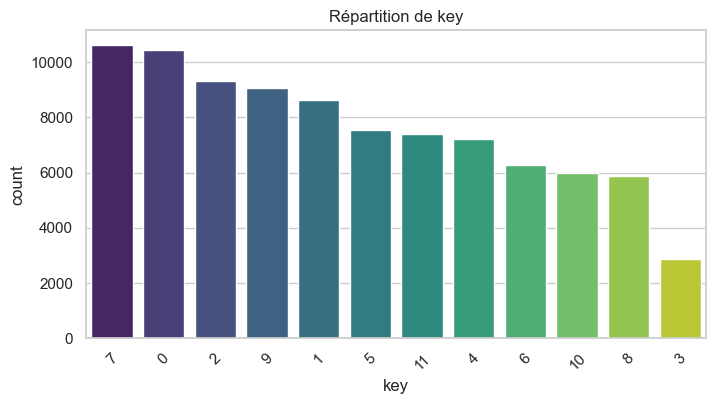

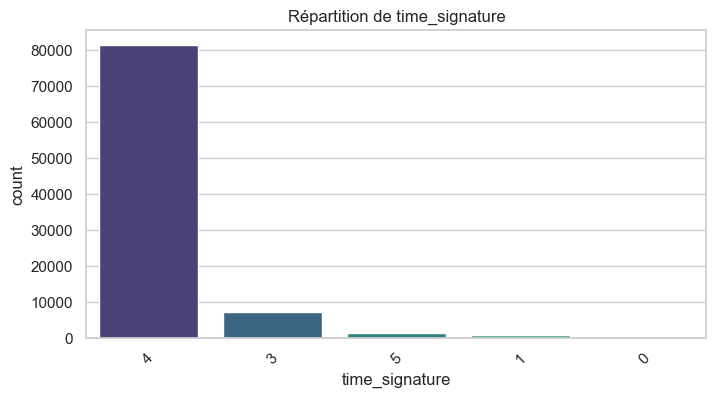

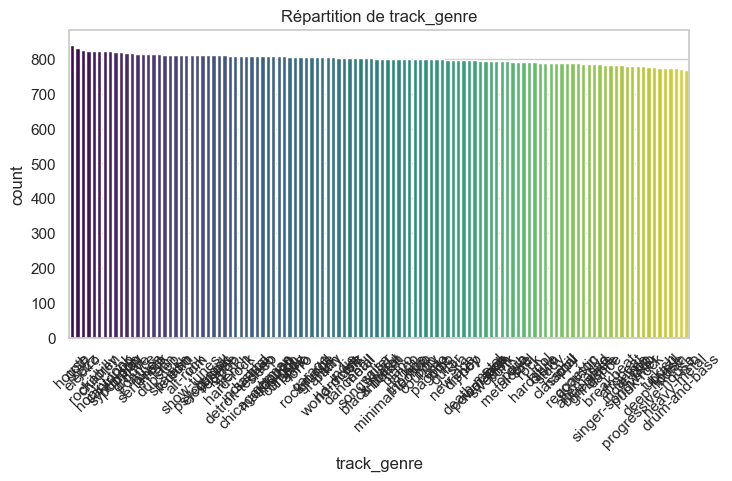

In [35]:
# 2. Répartition des variables catégorielles principales
train['key'] = train['key'].astype('category')
train['time_signature'] = train['time_signature'].astype('category')
cat_cols = train.select_dtypes(include=['object', 'category']).columns

for col in cat_cols:
    if train[col].nunique() <= 150:  # Limiter aux colonnes avec peu de catégories
        plt.figure(figsize=(8, 4))
        sns.countplot(data=train, x=col, order=train[col].value_counts().index, palette='viridis')
        plt.title(f'Répartition de {col}')
        plt.xticks(rotation=45)
        plt.show()

À COMMENTER

L'analyse se concentre sur la distribution de la variable cible (`popularity`) afin d'identifier d'éventuelles asymétries ou valeurs nulles massives, ainsi que sur la matrice de corrélation des caractéristiques audio numériques.

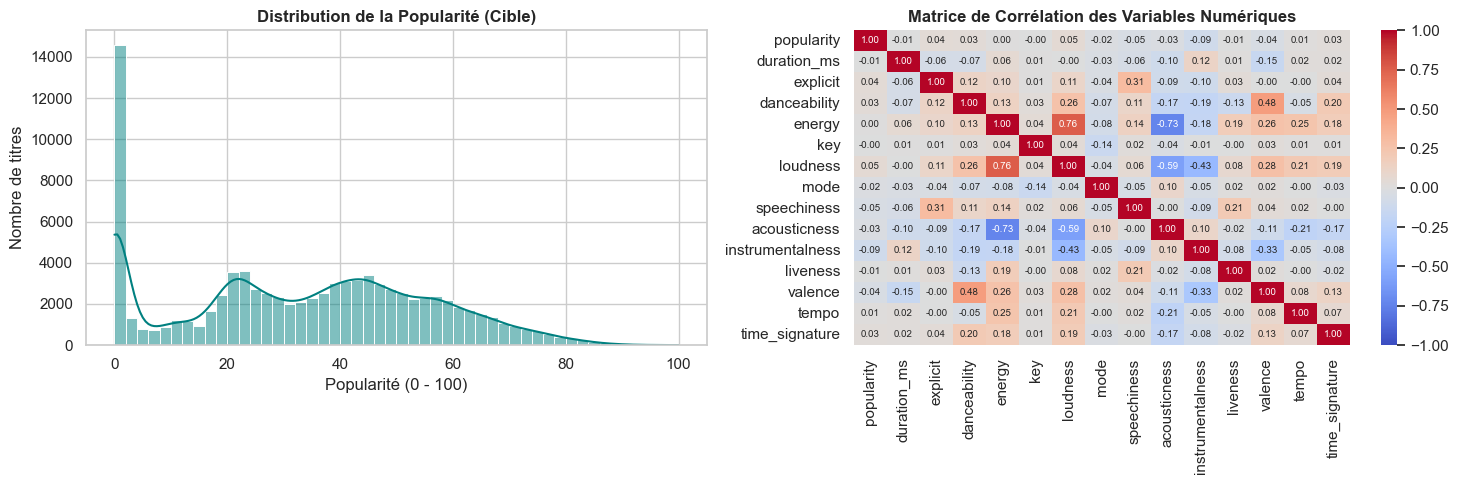

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Distribution of the Target Variable (Popularity)
sns.histplot(train_clean['popularity'], bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title("Distribution de la Popularité (Cible)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Popularité (0 - 100)")
axes[0].set_ylabel("Nombre de titres")

numeric_cols = train_clean.select_dtypes(include=[np.number]).columns
corr_matrix = train_clean[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7},ax=axes[1])
axes[1].set_title("Matrice de Corrélation des Variables Numériques", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

the correlation matrix is not looking good. It proves that a simple linear model (like Linear Regression) would completely fail here, which mathematically justifies using non-linear tree-based models.
Strong Collinearity Between Features: energy and loudness are strongly positively correlated ($0.76$), while energy and acousticness ($-0.73$) as well as loudness and acousticness ($-0.59$) are strongly negatively correlated. Decision trees handle collinearity well, though it slightly dilutes feature importance in Random Forests.  

## 3. Ingénierie des Variables et Encodage Catégoriel
Aucune valeur manquante n'étant présente, nous préparons les matrices finales en trois étapes :
1. **Regroupement binaire (`is_4_4_time`) :** La signature rythmique `time_signature` étant dominée à ~90% par la mesure standard $\frac{4}{4}$ (`4`), nous la simplifions en une variable indicatrice binaire (`1` si signature $= 4$, `0` sinon).
2. **One-Hot Encoding :** Application d'un encodage disjonctif complet sur les variables nominales `track_genre` (114 catégories) et `key` (12 tonalités musicales).

In [37]:
# 1. Séparation des features et de la cible
y_train = train_clean['popularity'].copy()
X_train_fe = train_clean.drop(columns=['popularity']).copy()
X_test_fe = test_clean.copy()

# 2. Feature Engineering: Création d'une variable binaire pour la mesure 4/4
X_train_fe['is_4_4_time'] = (X_train_fe['time_signature'].astype(str) == '4').astype(int)
X_test_fe['is_4_4_time'] = (X_test_fe['time_signature'].astype(str) == '4').astype(int)

X_train_fe.drop(columns=['time_signature'], inplace=True)
X_test_fe.drop(columns=['time_signature'], inplace=True)

# vérification Rapide
print("Proportion de titres en mesure 4/4 (Train) :")
print(X_train_fe['is_4_4_time'].value_counts(normalize=True).round(4))

Proportion de titres en mesure 4/4 (Train) :
is_4_4_time
1    0.8934
0    0.1066
Name: proportion, dtype: float64


In [38]:
# 3. 'key' et 'track_genre' transfromés en chaînes de caractères pour un encodage propre
X_train_fe['track_genre'] = X_train_fe['track_genre'].astype(str)
X_test_fe['track_genre'] = X_test_fe['track_genre'].astype(str)
X_train_fe['key'] = X_train_fe['key'].astype(str)
X_test_fe['key'] = X_test_fe['key'].astype(str)

cat_cols = ['track_genre', 'key']
num_cols = [col for col in X_train_fe.columns if col not in cat_cols]

# 4. One-Hot Encoding sur les variables catégorielles
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_cat = ohe.fit_transform(X_train_fe[cat_cols])
X_test_cat = ohe.transform(X_test_fe[cat_cols])

# Création des DataFrames encodés avec les noms de colonnes
ohe_cols = ohe.get_feature_names_out(cat_cols)
df_train_cat = pd.DataFrame(X_train_cat, columns=ohe_cols, index=X_train_fe.index)
df_test_cat = pd.DataFrame(X_test_cat, columns=ohe_cols, index=X_test_fe.index)

# 5. Regroupement des variables numériques et catégorielles encodées
X_train = pd.concat([X_train_fe[num_cols], df_train_cat], axis=1)
X_test = pd.concat([X_test_fe[num_cols], df_test_cat], axis=1)

print("y_train shape :", y_train.shape)
print("X_train shape :", X_train.shape)
print("X_test shape  :", X_test.shape)
display(X_train.head(3))

y_train shape : (91200,)
X_train shape : (91200, 139)
X_test shape  : (22800, 139)


,duration_ms,explicit,danceability,energy,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,is_4_4_time,track_genre_acoustic,track_genre_afrobeat,track_genre_alt-rock,track_genre_alternative,track_genre_ambient,track_genre_anime,track_genre_black-metal,track_genre_bluegrass,track_genre_blues,track_genre_brazil,track_genre_breakbeat,track_genre_british,track_genre_cantopop,track_genre_chicago-house,track_genre_children,track_genre_chill,track_genre_classical,track_genre_club,track_genre_comedy,track_genre_country,track_genre_dance,track_genre_dancehall,track_genre_death-metal,track_genre_deep-house,track_genre_detroit-techno,track_genre_disco,track_genre_disney,track_genre_drum-and-bass,track_genre_dub,track_genre_dubstep,track_genre_edm,track_genre_electro,track_genre_electronic,track_genre_emo,track_genre_folk,track_genre_forro,track_genre_french,track_genre_funk,track_genre_garage,track_genre_german,track_genre_gospel,track_genre_goth,track_genre_grindcore,track_genre_groove,track_genre_grunge,track_genre_guitar,track_genre_happy,track_genre_hard-rock,track_genre_hardcore,track_genre_hardstyle,track_genre_heavy-metal,track_genre_hip-hop,track_genre_honky-tonk,track_genre_house,track_genre_idm,track_genre_indian,track_genre_indie,track_genre_indie-pop,track_genre_industrial,track_genre_iranian,track_genre_j-dance,track_genre_j-idol,track_genre_j-pop,track_genre_j-rock,track_genre_jazz,track_genre_k-pop,track_genre_kids,track_genre_latin,track_genre_latino,track_genre_malay,track_genre_mandopop,track_genre_metal,track_genre_metalcore,track_genre_minimal-techno,track_genre_mpb,track_genre_new-age,track_genre_opera,track_genre_pagode,track_genre_party,track_genre_piano,track_genre_pop,track_genre_pop-film,track_genre_power-pop,track_genre_progressive-house,track_genre_psych-rock,track_genre_punk,track_genre_punk-rock,track_genre_r-n-b,track_genre_reggae,track_genre_reggaeton,track_genre_rock,track_genre_rock-n-roll,track_genre_rockabilly,track_genre_romance,track_genre_sad,track_genre_salsa,track_genre_samba,track_genre_sertanejo,track_genre_show-tunes,track_genre_singer-songwriter,track_genre_ska,track_genre_sleep,track_genre_songwriter,track_genre_soul,track_genre_spanish,track_genre_study,track_genre_swedish,track_genre_synth-pop,track_genre_tango,track_genre_techno,track_genre_trance,track_genre_trip-hop,track_genre_turkish,track_genre_world-music,key_0,key_1,key_10,key_11,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9
0,440247,0,0.369,0.598,-6.984,1,0.0304,0.00511,0.00000,0.176,0.0466,148.014,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,93933,0,0.171,0.997,-3.586,1,0.1180,0.00521,0.80100,0.420,0.0294,122.223,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,213578,0,0.173,0.803,-10.071,0,0.1440,0.61300,0.00191,0.195,0.0887,75.564,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,

## 4. Modélisation Classique : Arbre de Décision (`DecisionTreeRegressor`)

In [ ]:
# 1. la validation croisée à 10 plis 
kf = KFold(n_splits=10, shuffle=True, random_state=42)

# 2. Grille d'hyperparamètres à tester 
param_grid_dt = {'max_depth': [10, 15, 20, 25, 30, None],'max_features': [None, 'sqrt', 0.5, 0.8],'min_samples_leaf': [1, 5, 10, 20]}

# 3. Recherche par grille 
dt = DecisionTreeRegressor(random_state=42)
grid_dt = GridSearchCV(estimator=dt,param_grid=param_grid_dt,scoring='neg_root_mean_squared_error',cv=kf,n_jobs=-1,verbose=1)
grid_dt.fit(X_train, y_train)

# 4. Récupération du meilleur modèle et du score RMSE moyen sur les 10 plis
best_dt = grid_dt.best_estimator_
best_dt_rmse = -grid_dt.best_score_

print("Meilleurs hyperparamètres (Decision Tree) :", grid_dt.best_params_)
print(f"RMSE moyenne (10-Fold CV) : {best_dt_rmse:.4f}")

Fitting 10 folds for each of 96 candidates, totalling 960 fits
Meilleurs hyperparamètres (Decision Tree) : {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 20}
RMSE moyenne (10-Fold CV) : 18.7821


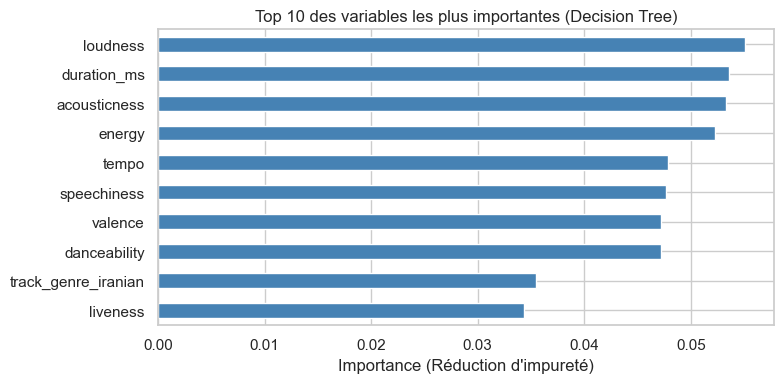

Fichier 'submission_dt.csv' généré avec succès !


In [40]:
# Affichage des 10 variables les plus importantes pour le meilleur arbre
importances = pd.Series(best_dt.feature_importances_, index=X_train.columns)
top_10_features = importances.sort_values(ascending=True).tail(10)

plt.figure(figsize=(8, 4))
top_10_features.plot(kind='barh', color='steelblue')
plt.title("Top 10 des variables les plus importantes (Decision Tree)")
plt.xlabel("Importance (Réduction d'impureté)")
plt.tight_layout()
plt.show()

# Génération des prédictions sur le jeu de test (clippées entre 0 et 100)
y_pred_dt = np.clip(best_dt.predict(X_test), 0, 100)

submission_dt = pd.DataFrame({
    'id': test_ids,
    'popularity': y_pred_dt
})
submission_dt.to_csv('submission_dt.csv', index=False)
print("Fichier 'submission_dt.csv' généré avec succès !")

**Interprétation des résultats (Decision Tree) :**  
La validation croisée à 10 plis retient un arbre non contraint en profondeur (`max_depth=None`), mais fortement régularisé par la taille minimale des feuilles (`min_samples_leaf=20`) et un sous-échantillonnage des variables (`max_features=0.5`), atteignant une **RMSE de validation de 18,78**. L'analyse d'importance montre que l'arbre s'appuie principalement sur les variables acoustiques continues (`loudness`, `duration_ms`, `acousticness`, `energy` représentant chacune ~5% de la réduction d'impureté), complétées par certains genres très discriminants comme `track_genre_iranian`.

In [46]:

# 1. Grille d'hyperparamètres à tester pour la Forêt Aléatoire
param_dist_rf = {
    'n_estimators': [100, 200],
    'max_depth': [15, 25, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 4, 8],
    'max_features': ['sqrt', 0.5, 0.8]
}

# 1. Recherche aléatoire (RandomizedSearchCV) optimisée sur la RMSE
rf = RandomForestRegressor(random_state=42, n_jobs=-1)

search_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist_rf,
    n_iter=15,
    scoring='neg_root_mean_squared_error',
    cv=kf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search_rf.fit(X_train, y_train)

# 4. Récupération du meilleur modèle et des scores RMSE
best_rf = search_rf.best_estimator_
best_rf_rmse = -search_rf.best_score_
rmse_train_rf = root_mean_squared_error(y_train, best_rf.predict(X_train))

print("Meilleurs hyperparamètres (Random Forest) :", search_rf.best_params_)
print(f"RMSE moyenne Random Forest (10-Fold CV)    : {best_rf_rmse:.4f}")
print(f"RMSE sur l'ensemble du jeu Train          : {rmse_train_rf:.4f}")
print(f"Gain par rapport au Decision Tree         : {best_dt_rmse - best_rf_rmse:.4f} points de RMSE")

Fitting 10 folds for each of 15 candidates, totalling 150 fits
Meilleurs hyperparamètres (Random Forest) : {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': None}
RMSE moyenne Random Forest (10-Fold CV)    : 15.5884
RMSE sur l'ensemble du jeu Train          : 7.4488
Gain par rapport au Decision Tree         : 3.1937 points de RMSE


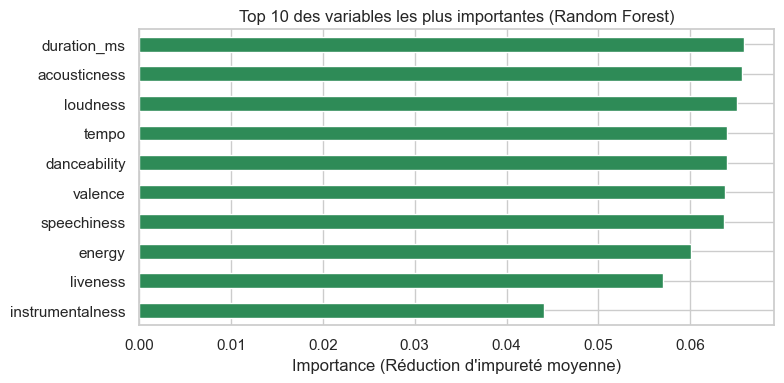

Fichier 'submission_rf_tuned.csv' généré avec succès !


In [48]:
# Affichage du Top 10 des variables les plus importantes pour la Random Forest
rf_importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
top_10_rf = rf_importances.sort_values(ascending=True).tail(10)

plt.figure(figsize=(8, 4))
top_10_rf.plot(kind='barh', color='seagreen')
plt.title("Top 10 des variables les plus importantes (Random Forest)")
plt.xlabel("Importance (Réduction d'impureté moyenne)")
plt.tight_layout()
plt.show()

# Génération des prédictions sur le jeu de test (clippées entre 0 et 100)
y_pred_rf = np.clip(best_rf.predict(X_test), 0, 100)

submission_rf = pd.DataFrame({
    'id': test_ids,
    'popularity': y_pred_rf
})
submission_rf.to_csv('submission_rf_tuned.csv', index=False)
print("Fichier 'submission_rf_tuned.csv' généré avec succès !")

## 5. Modélisation Avancée : Gradient Boosting (`XGBRegressor`)

In [49]:
from xgboost import XGBRegressor

# 1. Grille d'hyperparamètres pour XGBoost
param_dist_xgb = {
    'n_estimators': [600, 800, 1000],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [6, 8, 9],
    'subsample': [0.8, 1.0],          # Pourcentage de lignes tirées par arbre
    'colsample_bytree': [0.4, 0.5, 0.7],   # Équivalent de max_features pour chaque arbre
    'min_child_weight': [5, 10, 15]   # Équivalent de min_samples_leaf
}

# 2. Initialisation du modèle (tree_method='hist' accélère massivement le calcul)
xgb = XGBRegressor(
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

# 3. Recherche aléatoire sur les mêmes 10 plis (kf)
search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist_xgb,
    n_iter=12,  # Teste 12 combinaisons (12 x 10 = 120 fits)
    scoring='neg_root_mean_squared_error',
    cv=kf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search_xgb.fit(X_train, y_train)

# 4. Récupération du meilleur modèle et comparaison avec l'Arbre de Décision
best_xgb = search_xgb.best_estimator_
best_xgb_rmse = -search_xgb.best_score_

print("Meilleurs hyperparamètres (XGBoost) :", search_xgb.best_params_)
print(f"RMSE moyenne XGBoost (10-Fold CV)    : {best_xgb_rmse:.4f}")
print(f"Gain par rapport au Decision Tree    : {best_dt_rmse - best_xgb_rmse:.4f} points de RMSE")

Fitting 10 folds for each of 12 candidates, totalling 120 fits
Meilleurs hyperparamètres (XGBoost) : {'subsample': 0.8, 'n_estimators': 1000, 'min_child_weight': 10, 'max_depth': 9, 'learning_rate': 0.05, 'colsample_bytree': 0.5}
RMSE moyenne XGBoost (10-Fold CV)    : 16.2370
Gain par rapport au Decision Tree    : 2.5452 points de RMSE


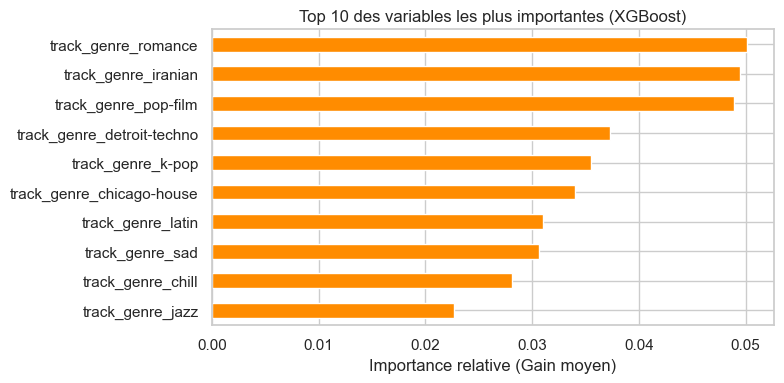

Fichier 'submission_xgb.csv' généré avec succès !


In [50]:
# Affichage du Top 10 des variables les plus importantes pour XGBoost
xgb_importances = pd.Series(best_xgb.feature_importances_, index=X_train.columns)
top_10_xgb = xgb_importances.sort_values(ascending=True).tail(10)

plt.figure(figsize=(8, 4))
top_10_xgb.plot(kind='barh', color='darkorange')
plt.title("Top 10 des variables les plus importantes (XGBoost)")
plt.xlabel("Importance relative (Gain moyen)")
plt.tight_layout()
plt.show()

# Génération des prédictions finales sur X_test (bornées entre 0 et 100)
y_pred_xgb = np.clip(best_xgb.predict(X_test), 0, 100)

submission_xgb = pd.DataFrame({
    'id': test_ids,
    'popularity': y_pred_xgb
})
submission_xgb.to_csv('submission_xgb.csv', index=False)
print("Fichier 'submission_xgb.csv' généré avec succès !")